# INSY 674 · KNN Modeling, Results and Interpretation

Predict whether an online shopping session ends in a purchase (`Revenue = 1`) using **K-nearest neighbors (KNN)**. The e-commerce analytics team can use the scores to rank sessions by purchase intent in an **offline whole-session benchmark**. This is supervised binary classification; the target is a purchase indicator, rather than order value. No incumbent business solution was supplied, so a constant-score majority reference is reported.

**Feature policy:** retain all **17 original predictors**, including `PageValues`, and exclude `source_row_id`. This matches the revised Random Forest scope. UCI lists PageValues as a feature, but the public description does not establish its timestamp or whether its calculation excludes each session's eventual purchase. Its inclusion is a benchmark decision; live pre-purchase availability remains unverified. [UCI dataset documentation](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset).

General EDA, original-source auditing and the team's other model families are handled elsewhere. This notebook covers KNN preparation, training, validation, tuning, results and interpretation. Restart the kernel and run cells from top to bottom. Each code chunk is followed by an English Markdown explanation. Numeric interpretations describe the saved run; refresh them after changing data or settings. Headings use `###` for a compact display.

### 1 · Install Packages If Needed

In [1]:
# %pip install "scikit-learn>=1.2" pandas numpy matplotlib cloudpickle threadpoolctl

The installation command is optional and commented out. Run it only if a package is missing. The saved run records its Python and scikit-learn versions in the next cell.

### 2 · Imports

In [2]:
from pathlib import Path
import json
import os
import platform
import tempfile

# Keep plotting and numerical libraries within predictable local resources.
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'insy674_mpl_cache'))
import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV, cross_validate,
    cross_val_predict, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from threadpoolctl import threadpool_limits

%matplotlib inline
# KNN CV runs several independent jobs; cap each job's numerical threads.
THREAD_LIMIT = threadpool_limits(limits=1)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.13.9 | scikit-learn: 1.7.2


KNN is a distance-based classifier. Unlike RF, it requires a deliberate distance representation: numeric scaling and categorical encoding are part of the fitted pipeline. The same software environment should be used when reloading a saved model.

### 3 · Model Configuration

In [3]:
USE_EXISTING_DATAFRAMES = False

def find_csv(filename):
    for path in [Path.cwd() / filename, Path.home() / 'Downloads' / filename]:
        if path.exists():
            return path
    raise FileNotFoundError(f'Cannot find {filename}. Set its path manually or place it beside the notebook.')

if not USE_EXISTING_DATAFRAMES:
    TRAIN_PATH = find_csv('train_raw.csv')
    TEST_PATH = find_csv('test_raw.csv')

OUT = Path.cwd() / 'knn_results'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
N_ITER = 12
JOBS = 2
THRESHOLD = 0.5
TEST_EVALUATED = False
print('Input mode:', 'existing train/test DataFrames' if USE_EXISTING_DATAFRAMES else 'CSV files')
print('Outputs:', OUT)
IMPORTANCE_SAMPLE_SIZE = 1000
IMPORTANCE_REPEATS = 5
BOOTSTRAP_REPEATS = 500
save_environment = {'python': platform.python_version(), 'scikit_learn': sklearn.__version__}
(OUT / 'environment.json').write_text(json.dumps(save_environment, indent=2))

Input mode: CSV files
Outputs: /Users/changsun/Documents/Codex/2026-10-27/jie/work/knn_results


51

Seed **42**, the existing train/test split and **five stratified CV folds** match RF. Random search will evaluate **12 candidates**. The classification threshold is fixed at **0.5** before evaluation; it is not optimized on the test set. Set `USE_EXISTING_DATAFRAMES = True` only when upstream cells already define raw `train` and `test` DataFrames. Otherwise, place the CSV files beside the notebook or in Downloads. Model outputs go to `knn_results/`.

### 4 · Model Fields and Evaluation Helpers

In [4]:
TARGET = 'Revenue'

ID = 'source_row_id'

CAT = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

NUM = ['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

FEATURES = NUM + CAT
EXCLUDED_FEATURES = {'source_row_id'}
assert len(FEATURES) == 17
assert not EXCLUDED_FEATURES.intersection(FEATURES), 'Excluded fields entered the predictor list.'

SCORING = {'ap': 'average_precision', 'roc_auc': 'roc_auc', 'precision': 'precision',
           'recall': 'recall', 'f1': 'f1', 'balanced_accuracy': 'balanced_accuracy'}

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding='utf-8')

def metric_row(y, p):
    pred = (p >= THRESHOLD).astype(int)
    return {'average_precision': average_precision_score(y,p), 'roc_auc': roc_auc_score(y,p),
        'accuracy': accuracy_score(y,pred), 'balanced_accuracy': balanced_accuracy_score(y,pred),
        'precision': precision_score(y,pred,zero_division=0), 'recall': recall_score(y,pred),
        'f1': f1_score(y,pred,zero_division=0), 'tn_fp_fn_tp': confusion_matrix(y,pred).ravel().tolist()}

LOG_CANDIDATES = ['Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues',
    'TotalPages', 'TotalDuration', 'DurationPerPage']

The raw inputs are **10 numeric fields** and **7 categorical fields**, including nominal browser, operating-system, region and traffic codes. PageValues is numeric and remains included in every candidate. Revenue is the target and the source-row ID is excluded.

**AP (average precision)** is the primary metric: it summarizes precision as recall increases and is useful when buyers are a minority. Higher AP and ROC-AUC are better. AP should be compared with purchase prevalence, rather than interpreting it as accuracy. Precision measures how many predicted buyers actually purchase; recall measures how many actual buyers are found. F1 balances precision and recall. The fixed threshold does not claim to maximize business profit.

### 5 · Load Inputs and Check the Modeling Boundary

In [5]:
if USE_EXISTING_DATAFRAMES:
    if 'train' not in globals() or 'test' not in globals():
        raise RuntimeError('Run the upstream cells that define train and test DataFrames first.')
    train, test = train.copy(), test.copy()
else:
    train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)

for name, data in [('train', train), ('test', test)]:
    if not isinstance(data, pd.DataFrame):
        raise TypeError(f'{name} must be a pandas DataFrame.')
    missing = set(FEATURES + [TARGET]) - set(data.columns)
    if missing:
        raise ValueError(f'{name}: missing required raw fields: {sorted(missing)}')
    if data.empty or data[TARGET].isna().any() or set(data[TARGET].unique()) != {0, 1}:
        raise ValueError(f'{name}: Revenue must contain both 0 and 1, with no missing labels.')
    if ID in data and (data[ID].isna().any() or not data[ID].is_unique):
        raise ValueError(f'{name}: source_row_id must be unique and nonmissing when supplied.')
if ID in train and ID in test and set(train[ID]) & set(test[ID]):
    raise ValueError('Train and test have overlapping source_row_id values.')
if not train[FEATURES].merge(test[FEATURES], on=FEATURES).empty:
    raise ValueError('Train and test contain identical predictor records; investigate before modeling.')

for name, data in [('train', train), ('test', test)]:
    if data.columns.duplicated().any():
        raise ValueError(f'{name}: duplicate column names are not supported.')
    for field in NUM:
        values = data[field].dropna()
        if not pd.api.types.is_numeric_dtype(data[field]):
            raise TypeError(f'{name}: {field} must be numeric; supply the raw columns.')
        if not np.isfinite(values.to_numpy(dtype=float)).all() or (values < 0).any():
            raise ValueError(f'{name}: {field} must be finite and nonnegative when present.')

input_summary = pd.DataFrame({
    'split': ['train', 'test'], 'rows': [len(train), len(test)],
    'purchases': [int(train[TARGET].sum()), int(test[TARGET].sum())],
    'purchase_rate': [train[TARGET].mean(), test[TARGET].mean()],
})
input_summary.to_csv(OUT / 'model_input_summary.csv', index=False)
display(input_summary)
print('KNN input checks passed. Only the 17 allowed predictors (including PageValues) will enter the pipeline.')

,split,rows,purchases,purchase_rate
0,train,9764,1526,0.156288
1,test,2441,382,0.156493


KNN input checks passed. Only the 17 allowed predictors (including PageValues) will enter the pipeline.


The notebook uses **9,764 training sessions** and **2,441 test sessions**. Purchases represent **15.63%** of training sessions and **15.65%** of test sessions.

Required fields and labels are valid; source IDs and identical predictor records do not overlap across splits. Numeric inputs satisfy the finite, nonnegative requirements of the log option. These minimal boundary checks do not repeat EDA or prove prediction-time availability. General source auditing remains an upstream responsibility.

The random split assumes independent sessions representative of future use. The available inputs do not support strong temporal or repeated-user validation, and historical behavior can differ from future traffic.

### 6 · Define the KNN Preprocessing Pipeline

In [6]:
class KNNFeatures(BaseEstimator, TransformerMixin):
    """Stateless within-session engineering; no learned statistics or labels."""
    def __init__(self, engineered=False):
        self.engineered = engineered

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        z = X.loc[:, FEATURES].copy()
        assert 'PageValues' in z.columns and ID not in z.columns
        if self.engineered:
            counts = ['Administrative', 'Informational', 'ProductRelated']
            durations = [c + '_Duration' for c in counts]
            z['TotalPages'] = z[counts].sum(axis=1, min_count=len(counts))
            z['TotalDuration'] = z[durations].sum(axis=1, min_count=len(durations))
            z['ProductPageShare'] = z.ProductRelated / z.TotalPages.replace(0, 1)
            z['DurationPerPage'] = z.TotalDuration / z.TotalPages.replace(0, 1)
        for c in CAT:
            z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan).astype(object)
        return z

def skewed_columns(frame):
    return [c for c in frame.select_dtypes(include=np.number).columns if c in LOG_CANDIDATES]

def remaining_numeric_columns(frame):
    return [c for c in frame.select_dtypes(include=np.number).columns if c not in LOG_CANDIDATES]

def pipeline(engineered=False, log_skewed=False):
    log_step = FunctionTransformer(np.log1p, feature_names_out='one-to-one') if log_skewed else 'passthrough'
    preprocess = ColumnTransformer([
        ('skewed', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('log', log_step), ('scale', StandardScaler())]), skewed_columns),
        ('other_numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())]), remaining_numeric_columns),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT)
    ])
    return Pipeline([
        ('features', KNNFeatures(engineered=engineered)),
        ('preprocess', preprocess),
        ('knn', KNeighborsClassifier(n_neighbors=5, weights='uniform', p=2,
                                    metric='minkowski', algorithm='brute', n_jobs=1))
    ])

Numeric values are median-imputed and **standardized using training-fold means and standard deviations**. A log1p option compresses nonnegative counts, durations and PageValues before scaling. Bounded bounce/exit rates, SpecialDay and the optional product-page share are scaled without the log transform. No rows are removed as outliers.

Categorical codes are mode-imputed and one-hot encoded; their indicators remain 0/1 rather than giving rare categories large standardized values. Unknown categories are ignored at prediction time, which is a limitation if future category distributions change. Every learned transformation is fitted inside its CV training fold.

The optional engineering step matches RF: total pages, total duration, product-page share and duration per page. These correlated derived variables can reweight aspects of distance, so engineering and log choices are validated instead of assumed beneficial. The reference KNN uses **5 neighbors, uniform voting and Euclidean distance**. [KNN documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html), [StandardScaler documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

### 7 · Set Up Training-Only Validation and Verify Features

In [7]:
X, y = train[FEATURES].copy(), train[TARGET].astype(int).copy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}
fold_assignment = np.full(len(train), -1, dtype=int)
for fold, (_, valid_indices) in enumerate(cv.split(X, y), start=1):
    fold_assignment[valid_indices] = fold
pd.DataFrame({'record_id': train[ID].to_numpy() if ID in train else train.index.to_numpy(),
              'validation_fold': fold_assignment}).to_csv(OUT / 'cv_fold_assignments.csv', index=False)

def ensure_training_stage():
    if TEST_EVALUATED:
        raise RuntimeError('The final model has already been evaluated. Do not tune from test results. Restart only to reproduce the fixed procedure.')

def evaluate_knn_variant(label, engineered=False, log_skewed=False):
    ensure_training_stage()
    scores = cross_validate(pipeline(engineered=engineered, log_skewed=log_skewed), X, y,
                            scoring=SCORING, cv=cv, n_jobs=JOBS, error_score='raise')
    row = {'variant': label}
    for metric in SCORING:
        values = scores['test_' + metric]
        row[metric + '_mean'] = float(values.mean())
        row[metric + '_std'] = float(values.std(ddof=1))
    cv_results[label] = row
    return pd.DataFrame([row])

for use_engineering in [False, True]:
    preview = pipeline(engineered=use_engineering).named_steps['features'].transform(X.head())
    assert 'PageValues' in preview and ID not in preview
    print(f'Engineering={use_engineering}: {preview.shape[1]} inputs before encoding; PageValues included.')
save_json({'included_features': FEATURES, 'excluded_features': [ID],
           'prediction_scope': 'offline whole-session benchmark; PageValues timing unverified'},
          OUT / 'feature_policy.json')
print('Training predictors:', X.shape, '| Purchase rate:', round(y.mean(), 4))
print('External test labels are not used in model selection.')

Engineering=False: 17 inputs before encoding; PageValues included.
Engineering=True: 21 inputs before encoding; PageValues included.
Training predictors: (9764, 17) | Purchase rate: 0.1563
External test labels are not used in model selection.


Five-fold stratified CV supplies validation data **within the existing training set**, so a separate validation CSV is unnecessary. Each fold preserves the minority-buyer proportion approximately. Mean and **sample SD across the five folds** will be reported. The `test_ap` key in CV output refers to fold validation, not the external test CSV.

The feature checks enforce **17 raw inputs** or **21 inputs with engineering**, before one-hot encoding. Every variant retains PageValues and excludes the ID. The same seed, fold count and row order as RF give matching validation folds; fold assignments are exported for team integration.

### 8 · Cross-Validate the Scaled Reference KNN

In [8]:
display(evaluate_knn_variant('Scaled KNN'))

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Scaled KNN,0.478545,0.019863,0.783231,0.010294,0.664659,0.031209,0.371583,0.032799,0.475947,0.029411,0.668372,0.015548


The scaled 5-neighbor reference achieves **AP = 0.4785 ± 0.0199**, **ROC-AUC = 0.7832 ± 0.0103**, and **F1 = 0.4759 ± 0.0294** across five training-validation folds (mean ± sample SD). Precision is **66.47%** and recall is **37.16%** at threshold 0.5.

All 17 raw predictors, including PageValues, are present. Standardization removes differences in numeric units, but large skewed values can still affect relative distances. This provides the KNN reference before applying the log option.

### 9 · First Iteration: Log-Transform Skewed Inputs

In [9]:
display(evaluate_knn_variant('Log-scaled KNN', log_skewed=True))

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Log-scaled KNN,0.590443,0.018858,0.864391,0.010023,0.671437,0.021915,0.531482,0.026176,0.592631,0.012139,0.741524,0.010354


Log-transforming the designated nonnegative numeric inputs, followed by standardization, achieves **AP = 0.5904 ± 0.0189**, **ROC-AUC = 0.8644 ± 0.0100**, and **F1 = 0.5926 ± 0.0121**. Mean AP changes by **+0.1119** relative to the scaled reference. Precision is **67.14%** and recall is **53.15%**.

This iteration improves validation ranking. Log1p compresses large counts, durations and PageValues so that extreme numeric magnitudes have less influence on neighbor distances. The result supports this transformation on the current training folds; it is not a causal claim or a significance test.

### 10 · Second Iteration: Add Session-Level Features

In [10]:
display(evaluate_knn_variant('Engineered log-scaled KNN', engineered=True, log_skewed=True))

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Engineered log-scaled KNN,0.585023,0.016834,0.863564,0.004683,0.664396,0.026084,0.528848,0.022351,0.588345,0.012573,0.73954,0.008948


Adding total pages, total duration, product-page share and duration per page gives **AP = 0.5850 ± 0.0168**, **ROC-AUC = 0.8636 ± 0.0047**, and **F1 = 0.5883 ± 0.0126**. Mean AP changes by **-0.0054** relative to the log-scaled raw-input KNN. Precision is **66.44%**, and recall is **52.88%**.

Engineering does not improve this fixed 5-neighbor configuration. Derived variables overlap with existing inputs and can reweight distances; additional columns do not automatically improve KNN. Engineering remains a tuning option because it may interact with neighbor count and distance weighting. All variants retain PageValues.

### 11 · Compare KNN Validation Results

In [11]:
required_variants = ['Scaled KNN', 'Log-scaled KNN', 'Engineered log-scaled KNN']
missing = [name for name in required_variants if name not in cv_results]
if missing:
    raise RuntimeError(f'Run the preceding CV cells first: {missing}')
comparisons = pd.DataFrame([cv_results[name] for name in required_variants])
comparisons.to_csv(OUT / 'knn_variant_cv.csv', index=False)
display(comparisons.round(4))
print('Log-transform AP change:', round(comparisons.iloc[1].ap_mean - comparisons.iloc[0].ap_mean, 4))
print('Engineering AP change:', round(comparisons.iloc[2].ap_mean - comparisons.iloc[1].ap_mean, 4))
print('All variants use the same folds and include PageValues. Differences are descriptive, not significance tests.')

,variant,ap_mean,ap_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,Scaled KNN,0.4785,0.0199,0.7832,0.0103,0.6647,0.0312,0.3716,0.0328,0.4759,0.0294,0.6684,0.0155
1,Log-scaled KNN,0.5904,0.0189,0.8644,0.0100,0.6714,0.0219,0.5315,0.0262,0.5926,0.0121,0.7415,0.0104
2,Engineered log-scaled KNN,0.5850,0.0168,0.8636,0.0047,0.6644,0.0261,0.5288,0.0224,0.5883,0.0126,0.7395,0.0089


Log-transform AP change: 0.1119
Engineering AP change: -0.0054
All variants use the same folds and include PageValues. Differences are descriptive, not significance tests.


| KNN variant | AP | ROC-AUC | F1 |
|---|---:|---:|---:|
| Scaled KNN | 0.4785 ± 0.0199 | 0.7832 ± 0.0103 | 0.4759 ± 0.0294 |
| Log-scaled KNN | 0.5904 ± 0.0189 | 0.8644 ± 0.0100 | 0.5926 ± 0.0121 |
| Engineered log-scaled KNN | 0.5850 ± 0.0168 | 0.8636 ± 0.0047 | 0.5883 ± 0.0126 |

**Log-scaled KNN** has the highest mean AP among the three fixed-reference KNN variants. The log iteration changes AP by **+0.1119**; subsequent engineering changes it by **-0.0054**. These are two explicit model-preparation iterations on training validation. All use identical folds and retain PageValues.

Fold SDs describe variability, rather than confidence intervals. These descriptive differences do not establish statistical significance. The variants belong to one model family; the team's final comparison must include other families and explain its shortlist.

### 12 · Tune KNN and Transformation Choices

In [12]:
ensure_training_stage()
search = RandomizedSearchCV(pipeline(), {
    'features__engineered': [False, True],
    'preprocess__skewed__log': ['passthrough', FunctionTransformer(np.log1p, feature_names_out='one-to-one')],
    'knn__n_neighbors': [5, 11, 21, 35, 51, 75, 101],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}, n_iter=N_ITER, scoring=SCORING, refit='ap', cv=cv,
   n_jobs=JOBS, random_state=SEED, error_score='raise', return_train_score=True)
print('Randomized CV tuning...', flush=True)
search.fit(X, y)
best = search.best_estimator_  # Refit automatically on all training rows.
assert 'PageValues' in X and ID not in X
assert any('PageValues' in name for name in best.named_steps['preprocess'].get_feature_names_out())
tuning_results = pd.DataFrame(search.cv_results_)
tuning_results.to_csv(OUT / 'tuning_cv.csv', index=False)
selected_parameters = dict(search.best_params_)
selected_parameters['preprocess__skewed__log'] = (
    'log1p' if isinstance(best.named_steps['preprocess'].named_transformers_['skewed'].named_steps['log'], FunctionTransformer)
    else 'passthrough')
save_json(selected_parameters, OUT / 'best_parameters.json')
show_cols = ['rank_test_ap', 'mean_test_ap', 'std_test_ap', 'mean_test_roc_auc', 'mean_test_f1', 'params']
display(tuning_results[show_cols].sort_values('rank_test_ap').head(8))
print('Selected parameters:', selected_parameters)
print(f'Selected CV AP: {search.best_score_:.4f}')

Randomized CV tuning...


,rank_test_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,mean_test_f1,params
3,1,0.714796,0.018303,0.915767,0.589919,{'preprocess__skewed__log': FunctionTransforme...
11,2,0.713759,0.017383,0.915176,0.584745,{'preprocess__skewed__log': FunctionTransforme...
5,3,0.660987,0.014667,0.895792,0.593283,{'preprocess__skewed__log': FunctionTransforme...
7,4,0.655648,0.015532,0.885822,0.529056,{'preprocess__skewed__log': FunctionTransforme...
10,5,0.649919,0.013008,0.895879,0.489328,{'preprocess__skewed__log': FunctionTransforme...
1,6,0.616625,0.020815,0.881424,0.512204,{'preprocess__skewed__log': FunctionTransforme...
4,7,0.604696,0.008750,0.868622,0.224262,"{'preprocess__skewed__log': 'passthrough', 'kn..."
9,8,0.603814,0.008906,0.861443,0.399783,"{'preprocess__skewed__log': 'passthrough', 'kn..."


Selected parameters: {'preprocess__skewed__log': 'log1p', 'knn__weights': 'distance', 'knn__p': 2, 'knn__n_neighbors': 75, 'features__engineered': False}
Selected CV AP: 0.7148


Random search evaluates **12 parameter combinations across 5 stratified training folds**. It jointly explores neighbor count, voting weights, distance, log transformation and engineering, using AP for selection. This limits computation compared with the exhaustive **112-combination** grid. All candidates include PageValues, and every candidate's numeric values are standardized.

| Parameter | Selected setting |
|---|---|
| Neighbors (k) | 75 |
| Voting weights | distance |
| Distance | Euclidean (p = 2) |
| Skewed-input transformation | Log1p |
| Four engineered features | Excluded |

Selected mean validation **AP = 0.7148**. Smaller k can produce variable local decisions, while larger k smooths neighborhoods and may dilute the minority-buyer signal. Distance weighting gives closer neighbors more influence. Manhattan and Euclidean distances aggregate differences differently; their performance depends on the transformed representation. KNN does not provide the RF `class_weight` option.

The selected pipeline is refitted on all training sessions. The best CV score may be optimistic because those folds also selected the parameters; 12 random candidates do not guarantee the global optimum. The test set is not used to select the transformations, k, distance, weights or threshold.

### 13 · Diagnose Training Errors with OOF Predictions

In [13]:
ensure_training_stage()
print('Generating training out-of-fold diagnostics...', flush=True)
oof = cross_val_predict(best, X, y, cv=cv, method='predict_proba', n_jobs=JOBS)[:, 1]
trace_columns = ([ID] if ID in train.columns else []) + FEATURES + [TARGET]
train_errors = train[trace_columns].copy()
train_errors['oof_probability'] = oof
train_errors['oof_prediction'] = (oof >= THRESHOLD).astype(int)
train_errors['error_type'] = np.select(
    [(y == 1) & (oof < THRESHOLD), (y == 0) & (oof >= THRESHOLD)],
    ['false_negative', 'false_positive'], default='correct')
train_errors.to_csv(OUT / 'training_oof_diagnostics.csv', index=False)
display(train_errors['error_type'].value_counts().rename('count').to_frame())
display(train_errors.groupby('error_type')[NUM].median().round(3))
print('Selected-parameter OOF metrics:', metric_row(y, oof))

Generating training out-of-fold diagnostics...


,count
error_type,
correct,8720
false_negative,773
false_positive,271


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
error_type,,,,,,,,,,
correct,1.0,0.000,0.0,0.0,16.0,544.958,0.003,0.026,0.000,0.0
false_negative,3.0,68.733,0.0,0.0,39.0,1527.583,0.003,0.019,3.674,0.0
false_positive,3.0,69.033,0.0,0.0,30.0,1267.453,0.004,0.020,26.343,0.0


Selected-parameter OOF metrics: {'average_precision': 0.7118522665678471, 'roc_auc': 0.915341095845516, 'accuracy': 0.8930766079475625, 'balanced_accuracy': 0.7302752929953795, 'precision': 0.7353515625, 'recall': 0.49344692005242463, 'f1': 0.5905882352941176, 'tn_fp_fn_tp': [7967, 271, 773, 753]}


Selected-parameter OOF predictions contain **753 true positives**, **773 false negatives**, **271 false positives** and **7,967 true negatives**. Precision is **73.54%**, recall **49.34%**, F1 **0.5906**, and AP **0.7119** at threshold 0.5.

Each record is excluded from its fold's fit and preprocessing, but the same folds were used to choose hyperparameters. These are training diagnostics with selection optimism, rather than an unbiased nested-CV estimate. The error groups show where local voting misses buyers or assigns purchase scores to nonbuyers. Cart events, prices, stock, campaign exposure and exit reasons could help investigate these mistakes.

### 14 · Freeze the Selected KNN and Evaluate the Test Set

In [14]:
if not TEST_EVALUATED:
    frozen_model = best
    with (OUT / 'knn.pkl').open('wb') as f:
        cloudpickle.dump(frozen_model, f)
Xt, yt = test[FEATURES].copy(), test[TARGET].astype(int).copy()
assert 'PageValues' in Xt and ID not in Xt
p = frozen_model.predict_proba(Xt)[:, 1]
pred = (p >= THRESHOLD).astype(int)
metrics = metric_row(yt, p)
baseline = metric_row(yt, np.full(len(yt), float(y.mean())))
TEST_EVALUATED = True
save_json({'knn': metrics, 'majority_reference': baseline,
           'training_oof_selected_parameters_optimistic': metric_row(y, oof)}, OUT / 'metrics.json')
display(pd.DataFrame({'KNN': metrics, 'Majority reference': baseline}).drop(index='tn_fp_fn_tp'))
print('Confusion matrix order: TN, FP, FN, TP =', metrics['tn_fp_fn_tp'])
print('The model is frozen. Remaining cells report this fixed result only.')

,KNN,Majority reference
average_precision,0.712609,0.156493
roc_auc,0.915878,0.5
accuracy,0.896354,0.843507
balanced_accuracy,0.750935,0.5
precision,0.727915,0.0
recall,0.539267,0.0
f1,0.619549,0.0


Confusion matrix order: TN, FP, FN, TP = [1982, 77, 176, 206]
The model is frozen. Remaining cells report this fixed result only.


The frozen KNN uses PageValues and the fixed threshold **0.5**.

| Metric | Test result |
|---|---:|
| Average precision | 0.7126 |
| ROC-AUC | 0.9159 |
| Accuracy | 89.64% |
| Balanced accuracy | 75.09% |
| Precision | 72.79% |
| Recall | 53.93% |
| F1 | 0.6195 |

The constant-score majority reference has **84.35% accuracy**, but finds no buyers. Its AP is **0.1565**, compared with **0.7126** for KNN: an absolute AP difference of **+0.5561**. Thus, KNN provides purchase-intent ranking beyond a constant score on this sample. Selected CV AP is **0.7148**; the observed test-minus-CV difference is **-0.0022**.

This test split was already inspected in earlier RF experiments. It is a **reused holdout**, rather than a new independent confirmation. PageValues retention was fixed by the chosen benchmark scope before KNN fitting; no further model choices are made from these results. Scores have not been separately calibrated, and predictive discrimination does not show that outreach causes purchases or profit.

### 15 · Visualize Test Performance

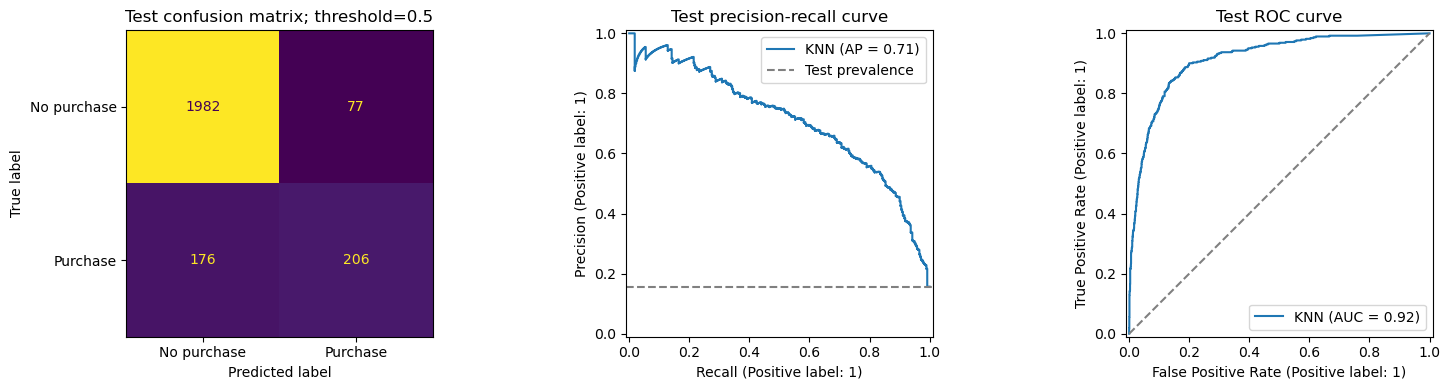

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(yt, pred, display_labels=['No purchase', 'Purchase'],
    ax=axes[0], colorbar=False)
axes[0].set_title(f'Test confusion matrix; threshold={THRESHOLD}')
PrecisionRecallDisplay.from_predictions(yt, p, ax=axes[1], name='KNN')
axes[1].axhline(yt.mean(), ls='--', color='gray', label='Test prevalence')
axes[1].legend(); axes[1].set_title('Test precision-recall curve')
RocCurveDisplay.from_predictions(yt, p, ax=axes[2], name='KNN')
axes[2].plot([0, 1], [0, 1], '--', color='gray'); axes[2].set_title('Test ROC curve')
fig.tight_layout(); fig.savefig(OUT / 'test_performance.png', dpi=150)
plt.show(); plt.close(fig)

| Actual outcome | Predicted no purchase | Predicted purchase |
|---|---:|---:|
| No purchase | 1,982 | 77 |
| Purchase | 176 | 206 |

KNN identifies **206 of 382 buyers (53.93% recall)**. Of **283 positive predictions**, **206 are buyers (72.79% precision)**. The **77 false positives** could consume unnecessary contact effort; **176 false negatives** represent missed buyers.

The PR curve shows the precision/recall trade-off, with purchase prevalence as a reference. ROC-AUC **0.9159** summarizes buyer/nonbuyer ranking across thresholds; it is not classification accuracy. The threshold remains at 0.5. A cost-based alternative would require specified costs and benefits and must be selected using training validation.

### 16 · Inspect Test Prediction Errors

In [16]:
predictions = pd.DataFrame({'record_id': test[ID].to_numpy() if ID in test else test.index.to_numpy(), TARGET: yt.to_numpy()})
predictions['purchase_probability']=p
predictions['predicted_revenue']=pred
predictions['error_type']=np.select([(yt==1)&(pred==0),(yt==0)&(pred==1)],['false_negative','false_positive'],default='correct')
predictions.to_csv(OUT/'test_predictions.csv',index=False)
# Reporting only: do not use the test errors to change features or parameters.
diagnostic = test[FEATURES].copy()
diagnostic['error_type']=predictions['error_type'].to_numpy()
diagnostic.groupby('error_type')[NUM].median().to_csv(OUT/'test_error_group_medians.csv')

display(predictions.head(10))
display(predictions['error_type'].value_counts().rename('count').to_frame())
display(diagnostic.groupby('error_type')[NUM].median().round(3))

,record_id,Revenue,purchase_probability,predicted_revenue,error_type
0,1,0,0.000000,0,correct
1,4,0,0.013373,0,correct
2,5,0,0.000000,0,correct
3,9,0,0.013477,0,correct
4,11,0,0.000000,0,correct
5,13,0,0.000000,0,correct
6,16,0,0.000000,0,correct
7,21,0,0.000000,0,correct
8,38,0,0.000000,0,correct
9,54,0,0.000000,0,correct


,count
error_type,
correct,2188
false_negative,176
false_positive,77


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
error_type,,,,,,,,,,
correct,1.0,0.000,0.0,0.0,17.0,527.317,0.003,0.027,0.000,0.0
false_negative,3.0,76.342,0.0,0.0,37.0,1403.393,0.003,0.021,2.886,0.0
false_positive,3.0,54.833,0.0,0.0,29.0,1067.795,0.001,0.017,23.510,0.0


Missed buyers have median PageValues **2.89** and product-page count **37**. False positives have median PageValues **23.51** and product-page count **29**. These group summaries are descriptive associations and can conceal substantial overlap between outcomes.

The exported predictions and error labels support review by the team. Cart additions, item prices, inventory, campaign exposure and reasons for leaving would help distinguish look-alike sessions with different outcomes. These test errors are reported after freezing the model and do not feed another feature or parameter iteration.

### 17 · Examine Local Neighbor Evidence

In [17]:
# Inspect up to two false negatives and two false positives after the model is frozen.
case_positions = []
for error_type in ['false_negative', 'false_positive']:
    case_positions.extend(np.flatnonzero(predictions.error_type.to_numpy() == error_type)[:2].tolist())
neighbor_rows = []
if case_positions:
    represented_cases = frozen_model[:-1].transform(Xt.iloc[case_positions])
    distances, neighbor_indices = frozen_model.named_steps['knn'].kneighbors(represented_cases)
    for row_number, position in enumerate(case_positions):
        neighbor_labels = y.iloc[neighbor_indices[row_number]].to_numpy()
        neighbor_rows.append({
            'record_id': predictions.iloc[position]['record_id'],
            'error_type': predictions.iloc[position]['error_type'],
            'actual_revenue': int(yt.iloc[position]),
            'purchase_score': float(p[position]),
            'neighbors': len(neighbor_labels),
            'purchasing_neighbors': int(neighbor_labels.sum()),
            'unweighted_purchase_fraction': float(neighbor_labels.mean()),
            'nearest_distance': float(distances[row_number].min()),
            'mean_neighbor_distance': float(distances[row_number].mean()),
        })
neighbor_diagnostics = pd.DataFrame(neighbor_rows)
neighbor_diagnostics.to_csv(OUT / 'neighbor_diagnostics.csv', index=False)
display(neighbor_diagnostics)
print('These cases illustrate local voting, not causal explanations or a representative error sample.')

,record_id,error_type,actual_revenue,purchase_score,neighbors,purchasing_neighbors,unweighted_purchase_fraction,nearest_distance,mean_neighbor_distance
0,188,false_negative,1,0.179828,75,13,0.173333,1.772467,2.408784
1,248,false_negative,1,0.251986,75,19,0.253333,1.465104,2.226777
2,675,false_positive,0,0.647012,75,49,0.653333,1.634246,2.605871
3,756,false_positive,0,0.503535,75,38,0.506667,2.150147,2.869152


These cases illustrate local voting, not causal explanations or a representative error sample.


KNN predicts using labels of nearby **training** sessions in the fitted transformed feature space. The table shows up to two missed buyers and two false purchase predictions, chosen in dataset order. Uniform voting uses the purchasing-neighbor fraction; distance weighting gives nearer observations more influence, so the unweighted fraction can differ from the reported score.

A mistaken prediction can occur when a session's local neighborhood has the opposite outcome. Distance is a model representation, rather than proof that two people behave identically. These examples illustrate the prediction mechanism and do not identify why a shopper purchased. Their outcomes are used only for reporting after the model was frozen.

### 18 · Explain KNN with Permutation Importance

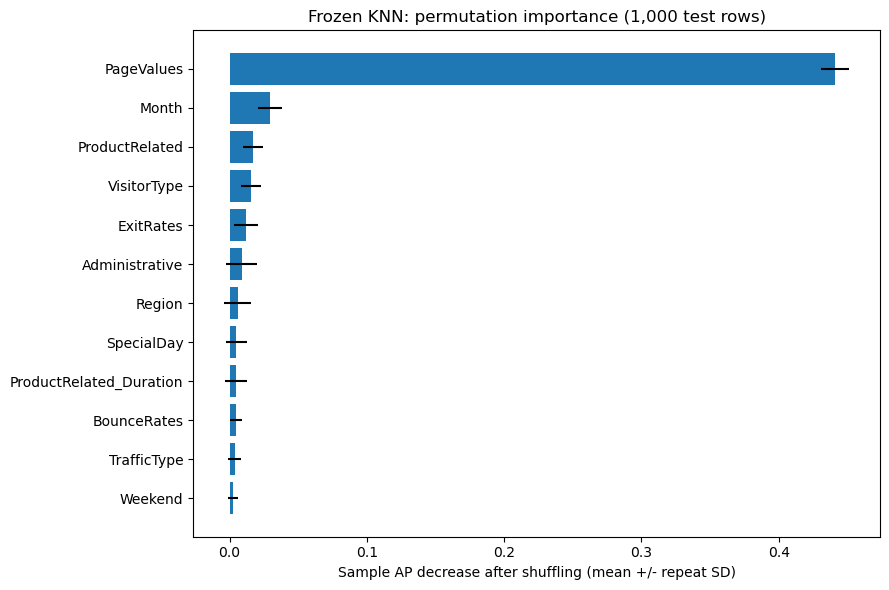

,feature,ap_drop_mean,ap_drop_std
8,PageValues,0.44096,0.01004
10,Month,0.02964,0.00867
4,ProductRelated,0.01699,0.00748
15,VisitorType,0.01567,0.00714
7,ExitRates,0.01177,0.00887
0,Administrative,0.00885,0.01128
13,Region,0.00587,0.00966
9,SpecialDay,0.00492,0.00780
5,ProductRelated_Duration,0.00472,0.00808
6,BounceRates,0.00454,0.00414


Importance sample: 1000 rows; unchanged-score AP: 0.6618


In [18]:
# Full test metrics above use every test row. This diagnostic uses a fixed stratified sample.
if len(Xt) > IMPORTANCE_SAMPLE_SIZE:
    importance_indices, _ = train_test_split(np.arange(len(Xt)), train_size=IMPORTANCE_SAMPLE_SIZE,
                                            stratify=yt.to_numpy(), random_state=SEED)
else:
    importance_indices = np.arange(len(Xt))
Xi, yi = Xt.iloc[importance_indices], yt.iloc[importance_indices]
importance_sample_ap = average_precision_score(yi, frozen_model.predict_proba(Xi)[:, 1])
importance = permutation_importance(frozen_model, Xi, yi, scoring='average_precision',
    n_repeats=IMPORTANCE_REPEATS, random_state=SEED, n_jobs=JOBS)
imp = pd.DataFrame({'feature': FEATURES, 'ap_drop_mean': importance.importances_mean,
                    'ap_drop_std': importance.importances_std}).sort_values('ap_drop_mean', ascending=False)
imp.to_csv(OUT / 'permutation_importance.csv', index=False)
save_json({'rows': len(Xi), 'purchase_rate': float(yi.mean()), 'sample_ap': importance_sample_ap,
           'repeats': IMPORTANCE_REPEATS}, OUT / 'importance_sample.json')
fig, ax = plt.subplots(figsize=(9, 6))
g = imp.head(12).iloc[::-1]
ax.barh(g.feature, g.ap_drop_mean, xerr=g.ap_drop_std)
ax.set(xlabel='Sample AP decrease after shuffling (mean +/- repeat SD)',
       title=f'Frozen KNN: permutation importance ({len(Xi):,} test rows)')
fig.tight_layout(); fig.savefig(OUT / 'feature_importance.png', dpi=150)
plt.show(); plt.close(fig)
display(imp.round(5))
print('Importance sample:', len(Xi), 'rows; unchanged-score AP:', round(importance_sample_ap, 4))

KNN has no tree-style built-in feature importance, so the frozen pipeline is assessed by shuffling each **raw input** and recomputing AP. Derived features are recomputed after the shuffle.

| Feature | Mean sample AP decrease after shuffling |
|---|---:|
| PageValues | 0.4410 |
| Month | 0.0296 |
| ProductRelated | 0.0170 |
| VisitorType | 0.0157 |
| ExitRates | 0.0118 |

The largest observed decrease is for **PageValues (0.4410)**. This identifies predictive dependence, rather than a causal effect or proof of prediction-time availability. Correlated inputs can share or distort importance; negative values can occur from shuffle noise.

To control repeated KNN prediction cost, this diagnostic uses a **fixed stratified sample of 1,000 test rows**, **5 shuffles per feature**, purchase prevalence **15.60%** and unshuffled sample AP **0.6618**. All headline metrics above use the full test set. The sample makes importance approximate; error bars show repeat-shuffle SDs, not confidence intervals. RF uses a different importance sample/repeat count, so importance magnitudes are not a controlled direct comparison. No feature is removed based on this test analysis.

### 19 · Quantify Fixed-Model Test Uncertainty

In [19]:
rng = np.random.default_rng(SEED)
ap_samples, auc_samples = [], []
yarr = yt.to_numpy()
for _ in range(BOOTSTRAP_REPEATS):
    ix = rng.integers(0, len(yt), len(yt))
    if np.unique(yarr[ix]).size == 2:
        ap_samples.append(average_precision_score(yarr[ix], p[ix]))
        auc_samples.append(roc_auc_score(yarr[ix], p[ix]))
intervals = {'ap_95pct': np.quantile(ap_samples, [.025, .975]).tolist(),
             'roc_auc_95pct': np.quantile(auc_samples, [.025, .975]).tolist()}
save_json(intervals, OUT / 'bootstrap_intervals.json')
display(pd.DataFrame(intervals, index=['lower 2.5%', 'upper 97.5%']).T)

,lower 2.5%,upper 97.5%
ap_95pct,0.665865,0.762111
roc_auc_95pct,0.899886,0.932039


Using **500 bootstrap resamples of all test rows**:

| Metric | Fixed-model 95% percentile interval |
|---|---|
| AP | 0.6659-0.7621 |
| ROC-AUC | 0.8999-0.9320 |

These intervals describe test-row sampling for the fixed model. They omit refitting, model selection, reuse of this holdout and future distribution shifts. Session independence is assumed. The public fields do not support a strong temporal evaluation or a fairness conclusion.

KNN retains the training representation and compares new sessions with stored examples; prediction cost grows with the reference data. One-hot encoding increases dimensionality, and irrelevant or correlated inputs can weaken distance-based similarity. Scores are local voting estimates with unverified calibration. PageValues and other whole-session fields require timestamp and construction checks before a live pre-purchase use case; an appropriately timed fresh test sample is needed for that deployment claim.

### 20 · Export the Model Contribution and Compare with RF If Available

In [20]:
model_summary = {'model': 'KNN', 'features': FEATURES, 'training_rows': len(X),
    'test_rows': len(Xt), 'cv_folds': cv.n_splits, 'seed': SEED, 'threshold': THRESHOLD,
    'selected_cv_ap': float(search.best_score_), 'parameters': selected_parameters,
    'test_metrics': metrics, 'pagevalues_policy': 'included; timing unverified',
    'scope': 'offline whole-session benchmark; reused holdout'}
save_json(model_summary, OUT / 'model_summary.json')
comparison_rows = [{'model': 'KNN', 'selected_cv_ap': float(search.best_score_),
    'test_ap': metrics['average_precision'], 'test_roc_auc': metrics['roc_auc'],
    'test_f1': metrics['f1'], 'test_precision': metrics['precision'], 'test_recall': metrics['recall']}]
rf_dir = OUT.parent / 'rf_pagevalues_results'
if all((rf_dir / name).exists() for name in ['feature_policy.json', 'metrics.json', 'tuning_cv.csv']):
    rf_policy = json.loads((rf_dir / 'feature_policy.json').read_text())
    if rf_policy.get('included_features') == FEATURES:
        rf_metrics = json.loads((rf_dir / 'metrics.json').read_text())['random_forest']
        rf_cv = pd.read_csv(rf_dir / 'tuning_cv.csv')
        comparison_rows.append({'model': 'Random Forest', 'selected_cv_ap': float(rf_cv.mean_test_ap.max()),
            'test_ap': rf_metrics['average_precision'], 'test_roc_auc': rf_metrics['roc_auc'],
            'test_f1': rf_metrics['f1'], 'test_precision': rf_metrics['precision'],
            'test_recall': rf_metrics['recall']})
model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv(OUT / 'team_model_comparison.csv', index=False)
display(model_comparison.round(4))
print('Saved model and reproducible outputs:', OUT)
print('Other model families, the team ensemble experiment and final shortlisting belong in the combined team analysis.')

,model,selected_cv_ap,test_ap,test_roc_auc,test_f1,test_precision,test_recall
0,KNN,0.7148,0.7126,0.9159,0.6195,0.7279,0.5393
1,Random Forest,0.7500,0.7421,0.9319,0.6676,0.7298,0.6152


Saved model and reproducible outputs: /Users/changsun/Documents/Codex/2026-10-27/jie/work/knn_results
Other model families, the team ensemble experiment and final shortlisting belong in the combined team analysis.


| Model | Selected CV AP | Test AP | Test ROC-AUC | Test F1 |
|---|---:|---:|---:|---:|
| KNN | 0.7148 | 0.7126 | 0.9159 | 0.6195 |
| Random Forest | 0.7500 | 0.7421 | 0.9319 | 0.6676 |

Under the current shared raw-feature policy and training-validation procedure, **Random Forest has the higher selected CV AP**. Test results are supplied as descriptive outcomes for the frozen models. The two searches each evaluate 12 candidates, while using model-appropriate preprocessing and different parameter spaces. This is not a statistical significance test, and neither family is guaranteed to be optimally tuned.

The fitted KNN, selected parameters, fold assignments, CV scores, predictions, errors, figures, importance and uncertainty intervals are exported to `knn_results/`. The saved model contains its preprocessing; do not standardize future raw inputs separately. Reload it with `cloudpickle.load` in a compatible environment.

This notebook provides the KNN contribution to the project checklist: objective and metric rationale, an automated preprocessing pipeline, N-fold mean/SD, two preparation iterations, CV tuning, held-out reporting, key-variable analysis and error interpretation. General EDA, the complete comparison across model families, the team's ensemble experiment and the final three-to-five-model shortlist belong in the combined project. RF supplies an ensemble model; any additional ensemble should be evaluated with training validation before test reporting.